# Classification des Régions par Genres Musicaux par le Deep Learning simple

## Introduction et Objectifs
Cette partie a pour objectif de prédire la région administrative (`y`) d'un individu ou d'un échantillon en fonction de ses préférences ou scores liés aux genres musicaux (`X`) en testant le deep learning. 

Les principales étapes de ce notebook sont :
1. **Prétraitement et mise à l'échelle** des données tabulaires.
2. **Entraînement d'un modèle de Deep Learning (MLP)**.
3. **Diagnostic et correction du déséquilibre de classes (*class imbalance*)**.
4. **Évaluation comparative** des performances (notamment via les métriques macro et la matrice de confusion).

## 2. Chargement et Préparation des Données

On va tester le modèle sur 3 variables cibles. D'abord, on va :
* Charger le jeu de données et vérifier sa structure.

Puis :
* Séparer les variables explicatives ($X$) de la variable cible ($Y$).
* Encoder les étiquettes et effectuer une division stratifiée en ensembles d'entraînement et de test (`train_test_split`).
* Normaliser les caractéristiques à l'aide de `StandardScaler` pour stabiliser l'apprentissage du réseau de neurones.

In [101]:
import pandas as pd

In [102]:
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

In [103]:
df = pd.read_csv("../Dataset/dataset_musique_region_transforme.csv")

In [104]:
df.head()

,variete_francaise,pop_rock,rap_hip_hop,classique,jazz,dance,electronique,metal,rnb,soul,reggae,musiques_du_monde,autres_genres,region,region_group,region_group_cardinal,total_genres
0,1,0,0,0,1,0,0,0,0,1,0,0,0,Occitanie,SUD,SUD,3
1,0,1,0,0,1,0,0,0,0,0,0,1,0,Pays de la Loire,CENTRE,OUEST,3
2,1,1,1,0,0,0,0,0,1,0,0,0,0,Hauts-de-France,NORD-OUEST,NORD,4
3,1,0,0,1,0,0,0,0,0,0,0,0,0,Provence-Alpes-Côte d'Azur,SUD,SUD,2
4,1,0,0,0,1,0,0,0,0,0,0,1,0,Auvergne-Rhône-Alpes,Auvergne-Rhône-Alpes,CENTRE,3


In [105]:
genres = [
    "variete_francaise", "pop_rock", "rap_hip_hop",
    "classique", "jazz", "dance", "electronique",
    "metal", "rnb", "soul", "reggae",
    "musiques_du_monde", "autres_genres"
]

X = df[genres].astype("float32")

## Entraînement sur les régions administratives

On commence par entraîner le modèle sur les régions administratives, on cherche donc à localiser l'individu finement.

In [107]:
# Cible : région administrative
encoder = LabelEncoder()
y1 = encoder.fit_transform(df["region"])

In [108]:
# Séparation apprentissage / test
X_train, X_test, y1_train, y1_test = train_test_split(
    X, y1,
    test_size=0.20,
    random_state=42,
    stratify=y1
)

In [109]:
from sklearn.preprocessing import StandardScaler

# Initialisation du scaler
scaler = StandardScaler()

# Ajustement et transformation sur le jeu d'entraînement, transformation simple sur le test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

On utilise une fonction de création de modèle qui prend pour argument le nombre de classes de la variable cible, car ce nombre varie en fonction du groupement choisi.

In [ ]:
def create_model(nb_classes):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(13,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(nb_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
# Réseau de neurones
model1 = create_model(len(encoder.classes_))

model1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Gestion du déséquilibre des classes et Early Stopping
- On a un fort déséquilbre des classes, avec l'Île-de-France représentée majoritairement. On pondère alors les classes, en attribuant un poids plus important aux classes minoritaires pour pénaliser sévèrement les erreurs commises sur celles-ci lors du calcul de la fonciton de perte.
- On évite le surapprentissage en stoppant l'entraînement lorsque la validation ne s'améliore plus.

In [111]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Calcul des poids pour la région administrative (y1)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y1_train),
    y=y1_train
)
class_weights_dict = dict(enumerate(class_weights))

In [112]:
# Entraînement
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

training1 = model1.fit(
    X_train_scaled, y1_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weights_dict,
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.0731 - loss: 2.6347 - val_accuracy: 0.1006 - val_loss: 2.5314
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0780 - loss: 2.5205 - val_accuracy: 0.0912 - val_loss: 2.5105
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0989 - loss: 2.4636 - val_accuracy: 0.0755 - val_loss: 2.5056
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1327 - loss: 2.4678 - val_accuracy: 0.0818 - val_loss: 2.5032
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1387 - loss: 2.4043 - val_accuracy: 0.0849 - val_loss: 2.5022
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1418 - loss: 2.4250 - val_accuracy: 0.0723 - val_loss: 2.5100
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1348 - loss: 2.4536 - val_accuracy: 0.0786 - val_loss: 2.5086
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1451 - loss: 2.4235 - val_accuracy: 0.0818 - 

Minimum validation loss: 2.4988949298858643


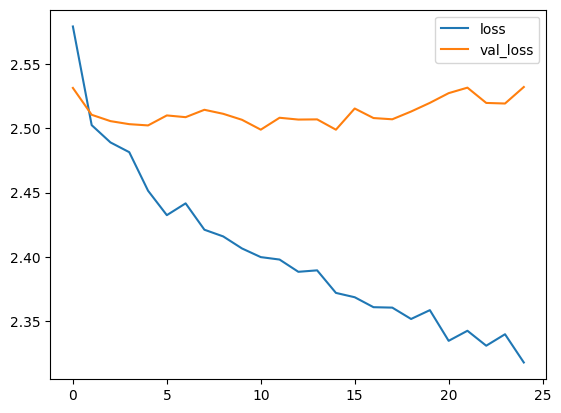

In [113]:
training1_df = pd.DataFrame(training1.history)
training1_df.loc[:, ['loss', 'val_loss']].plot();
print("Minimum validation loss: {}".format(training1_df['val_loss'].min()))

### Évaluation des Performances

L'évaluation ne doit pas se baser uniquement sur l'**Accuracy globale**, qui est trompeuse en cas de déséquilibre, mais sur :
* Le **Rapport de classification (`classification_report`)** en regardant spécifiquement le `macro avg` et le `weighted avg`.
* La **Matrice de confusion** pour visualiser précisément les confusions commises par le modèle entre les différentes régions.

In [114]:
# Évaluation
probabilities = model1.predict(X_test_scaled)
y1_pred = probabilities.argmax(axis=1)

print(classification_report(
    y1_test,
    y1_pred,
    labels=range(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.15      0.09      0.11        47
   Bourgogne-Franche-Comté       0.06      0.29      0.10        17
                  Bretagne       0.00      0.00      0.00        19
       Centre-Val de Loire       0.00      0.00      0.00        16
                 Grand Est       0.09      0.03      0.04        40
           Hauts-de-France       0.07      0.08      0.07        38
                 Normandie       0.03      0.11      0.05        18
        Nouvelle-Aquitaine       0.05      0.05      0.05        39
                 Occitanie       0.04      0.03      0.04        32
          Pays de la Loire       0.00      0.00      0.00        25
Provence-Alpes-Côte d'Azur       0.13      0.15      0.14        26
             Île-de-France       0.36      0.19      0.24        81

                  accuracy                           0.09       398
       

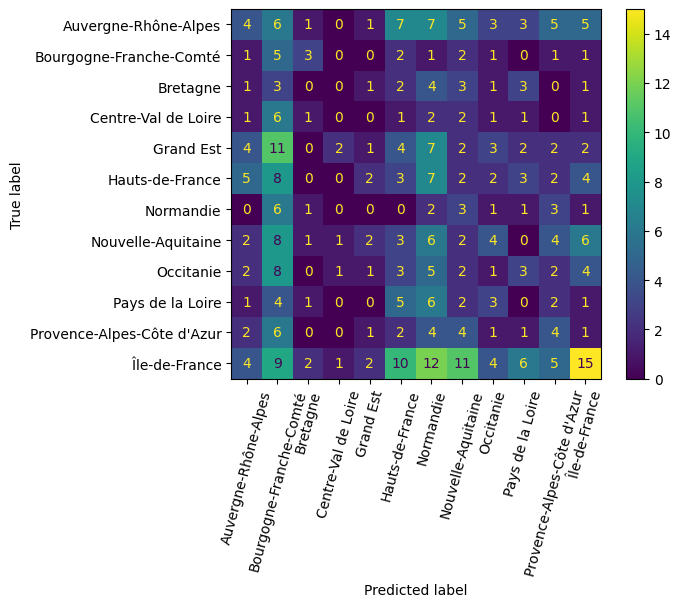

In [115]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y1_test,
    y1_pred,
    display_labels=encoder.classes_,
    xticks_rotation=75,
)

plt.show()

On réitère le processus pour les différents groupements.

## Premier regroupement des régions

In [70]:
# Cible : région administrative
encoder2 = LabelEncoder()
y2 = encoder2.fit_transform(df["region_group"])

In [71]:
# Séparation apprentissage / test
X_train, X_test, y2_train, y2_test = train_test_split(
    X, y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

In [94]:
# Initialisation du scaler
scaler = StandardScaler()

# Ajustement et transformation sur le jeu d'entraînement, transformation simple sur le test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [72]:
# Réseau de neurones
model2 = create_model(len(encoder2.classes_))

model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [116]:
# Calcul des poids pour le groupement (y2)
class_weights2 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y2_train),
    y=y2_train
)
class_weights_dict2 = dict(enumerate(class_weights2))

In [117]:
# Entraînement
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

training2 = model2.fit(
    X_train_scaled, y2_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weights_dict2,
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1880 - loss: 2.0714 - val_accuracy: 0.1384 - val_loss: 1.9903
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1147 - loss: 2.0062 - val_accuracy: 0.1101 - val_loss: 1.9852
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1663 - loss: 1.9290 - val_accuracy: 0.1164 - val_loss: 1.9800
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1696 - loss: 1.9507 - val_accuracy: 0.1132 - val_loss: 1.9783
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1855 - loss: 1.9328 - val_accuracy: 0.1195 - val_loss: 1.9804
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1590 - loss: 1.9226 - val_accuracy: 0.1226 - val_loss: 1.9887
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1913 - loss: 1.9263 - val_accuracy: 0.1321 - val_loss: 1.9833
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2349 - loss: 1.8949 - val_accuracy: 0.1195 - v

Minimum validation loss: 1.97830331325531


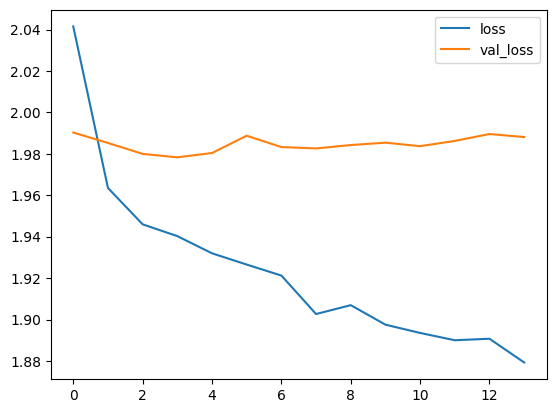

In [118]:
training2_df = pd.DataFrame(training2.history)
training2_df.loc[:, ['loss', 'val_loss']].plot();
print("Minimum validation loss: {}".format(training2_df['val_loss'].min()))

In [119]:
# Évaluation
probabilities = model2.predict(X_test_scaled)
y2_pred = probabilities.argmax(axis=1)

print(classification_report(
    y2_test,
    y2_pred,
    labels=range(len(encoder2.classes_)),
    target_names=encoder2.classes_,
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
                      precision    recall  f1-score   support

Auvergne-Rhône-Alpes       0.19      0.21      0.20        47
              CENTRE       0.19      0.16      0.17        58
           Grand Est       0.11      0.35      0.17        40
          NORD-OUEST       0.29      0.03      0.05        75
  Nouvelle-Aquitaine       0.08      0.08      0.08        39
                 SUD       0.14      0.26      0.18        58
       Île-de-France       0.24      0.06      0.10        81

            accuracy                           0.15       398
           macro avg       0.18      0.16      0.14       398
        weighted avg       0.19      0.15      0.13       398



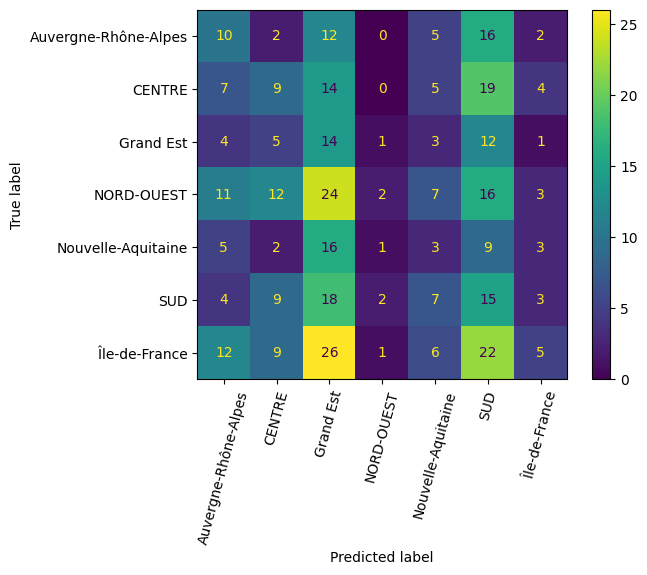

In [120]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y2_test,
    y2_pred,
    display_labels=encoder2.classes_,
    xticks_rotation=75,
)

plt.show()

## Deuxieme regroupement cardinal des régions

In [76]:
# Cible : région administrative
encoder3 = LabelEncoder()
y3 = encoder3.fit_transform(df["region_group_cardinal"])

In [77]:
# Séparation apprentissage / test
X_train, X_test, y3_train, y3_test = train_test_split(
    X, y3,
    test_size=0.20,
    random_state=42,
    stratify=y3
)

In [95]:
# Initialisation du scaler
scaler = StandardScaler()

# Ajustement et transformation sur le jeu d'entraînement, transformation simple sur le test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [78]:
# Réseau de neurones
model3 = create_model(len(encoder3.classes_))

model3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [123]:
# Calcul des poids pour le deuxieme groupement (y3)
class_weights3 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y3_train),
    y=y3_train
)
class_weights_dict3 = dict(enumerate(class_weights3))

In [124]:
# Entraînement
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

training3 = model3.fit(
    X_train_scaled, y3_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weights_dict3,
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1669 - loss: 1.8988 - val_accuracy: 0.1195 - val_loss: 1.8390
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2086 - loss: 1.8005 - val_accuracy: 0.1509 - val_loss: 1.8242
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1861 - loss: 1.8005 - val_accuracy: 0.1667 - val_loss: 1.8186
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2041 - loss: 1.7718 - val_accuracy: 0.1352 - val_loss: 1.8203
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2072 - loss: 1.7770 - val_accuracy: 0.1541 - val_loss: 1.8209
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2027 - loss: 1.7830 - val_accuracy: 0.1478 - val_loss: 1.8245
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2251 - loss: 1.7681 - val_accuracy: 0.1447 - val_loss: 1.8272
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2211 - loss: 1.7598 - val_accuracy: 0.1572 - v

Minimum validation loss: 1.8186455965042114


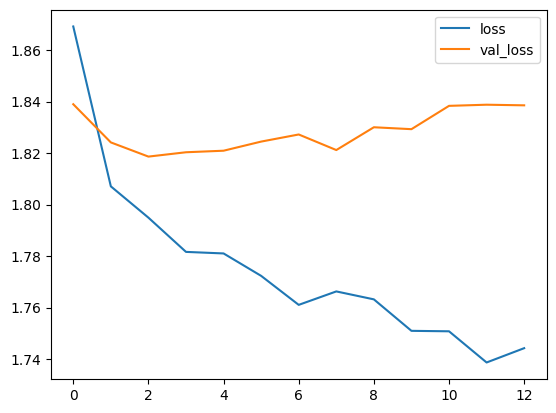

In [125]:
training3_df = pd.DataFrame(training3.history)
training3_df.loc[:, ['loss', 'val_loss']].plot();
print("Minimum validation loss: {}".format(training3_df['val_loss'].min()))

In [126]:
# Évaluation
probabilities = model3.predict(X_test_scaled)
y3_pred = probabilities.argmax(axis=1)

print(classification_report(
    y3_test,
    y3_pred,
    labels=range(len(encoder3.classes_)),
    target_names=encoder3.classes_,
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
               precision    recall  f1-score   support

       CENTRE       0.16      0.35      0.22        63
          EST       0.20      0.16      0.17        57
         NORD       0.18      0.25      0.21        56
        OUEST       0.14      0.11      0.12        83
          SUD       0.06      0.02      0.03        58
Île-de-France       0.27      0.19      0.22        81

     accuracy                           0.18       398
    macro avg       0.17      0.18      0.16       398
 weighted avg       0.17      0.18      0.16       398



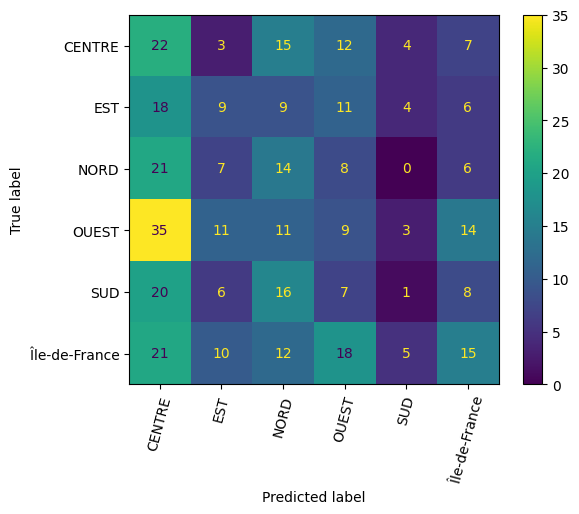

In [127]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y3_test,
    y3_pred,
    display_labels=encoder3.classes_,
    xticks_rotation=75,
)

plt.show()

# Comparaison

In [128]:
from sklearn.metrics import accuracy_score, f1_score

resultats = pd.DataFrame({
    "Modèle": [
        "Régions administratives",
        "Premier regroupement",
        "Deuxième regroupement"
    ],
    "Accuracy": [
        accuracy_score(y1_test, y1_pred),
        accuracy_score(y2_test, y2_pred),
        accuracy_score(y3_test, y3_pred)
    ],
    "F1 macro": [
        f1_score(y1_test, y1_pred, average="macro"),
        f1_score(y2_test, y2_pred, average="macro"),
        f1_score(y3_test, y3_pred, average="macro")
    ]
})

resultats

,Modèle,Accuracy,F1 macro
0,Régions administratives,0.092965,0.070607
1,Premier regroupement,0.145729,0.135286
2,Deuxième regroupement,0.175879,0.162092


# Conclusion

L'objectif de ce travail était d'étudier dans quelle mesure les préférences musicales d'un individu pouvaient permettre de prédire sa région géographique à l'aide de modèles de classification, et notamment de réseaux de neurones.

Trois expérimentations ont été réalisées, avec différents niveaux de regroupement géographique : les régions administratives, un premier regroupement géographique et un deuxième regroupement plus simplifié.

Avec les résultats obtenus après pondération des classes, on observe une progression des performances lorsque les catégories géographiques sont regroupées.
Le deuxième groupement obtient les meilleurs résultats, avec une accuracy de 17,59 % et un F1-score macro de 0.162. Cela suggère que la simplification des catégories géographiques facilite la tâche de classification.

Cependant, les performances restent globalement faibles. La pondération des classes ne permet pas à elle seule d'obtenir une classification satisfaisante.

On peut en déduire que les 13 variables musicales sélectionnées ne contiennent pas suffisament d'informations discriminantes pour identifier précisément la localisation géographique des individus. Les préférences musicales peuvent présenter des similitudes entre des individus de régions différentes, ce qui limite la capacité de généralisation des modèles.